# 1. Built-in signatures: from a signature to cell lines to drugs

`anchorline` anchors a query (a signature, a patient sample or single-cell data) to the closest untreated AML cell
lines in the drug-perturbation atlas. It then ranks the drugs tested in those lines by how much they change the cells,
whether they reverse the query signature, and how far they move the cells along the stem → myeloid axis.

The workflow has two steps, each computed once (`al.tl`), and plot functions that only choose what to show (`al.pl`):

```
mt = al.tl.match(atlas, query)              # rank all cell lines   -> al.pl.match_ranking, al.pl.pseudotime
dr = al.tl.rank_drugs(atlas, mt, cell_lines=5)   # rank drugs in them -> al.pl.drug_ranking, drug_shifts, state_map,
                                                 #                       class_trends, class_shift_map, gene_changes, ...
```
Every plot takes `n_top=` (how many) or explicit names (`cell_lines=`, `drugs=`, `classes=`), plus `figsize`,
`palette`, `cmap`, `fontsize`, `title`, `ax`, `save` and `show`.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import pandas as pd
import anchorline as al

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 20); pd.set_option("display.max_colwidth", 60)
al.settings.figdir = "figures"          # save=True writes here
al.settings.set_figure_params(fontsize=8.5, dpi=150)
atlas = al.load()                       # first time: downloads the atlas (~560 MB) to al.settings.data_dir
atlas

loading atlas from /Users/sina.kanannejad/.anchorline/data (~1-2 min, ~1.5 GB RAM)
  8894 reference samples (2805 untreated), 42003 genes; 1608 drug-vs-control contrasts


anchorline Atlas (/Users/sina.kanannejad/.anchorline/data)
  reference: 8894 samples (2805 untreated) x 42003 genes
  contrasts: 1608 (226 studies, 63 models, 363 drugs)

## The signature library
`al.sig.list()` shows every bundled signature with its source. Collections:
- **Umeda2024_pediatric_AML**: 20 pediatric AML groups (Umeda et al. 2024 *Nat Genet* 56:281–293, doi:10.1038/s41588-023-01640-3), top 50 protein-coding genes per group, up and down.
- **Zeng2022_AML_hierarchy**: the AML cell-type signatures behind the pseudotime axis (Zeng et al. 2022 *Nat Med* 28:1212–1223, doi:10.1038/s41591-022-01819-x).
- **stemness**:
  - LSC104 (Ng et al. 2016 *Nature* 540:433–437, doi:10.1038/nature20598);
  - MLL-LSC (Somervaille et al. 2009 *Cell Stem Cell* 4:129–140, doi:10.1016/j.stem.2008.11.015);
  - HSC_Cycle_Primed (source not verified).
- **menin_targets**: the HOXA/MEIS1 core (Issa et al. 2023 *Nature* 615:920–924, doi:10.1038/s41586-023-05812-3).

In [2]:
al.sig.collections()

collection
Umeda2024_pediatric_AML    20
Zeng2022_AML_hierarchy     13
menin_targets               1
stemness                    3
Name: n_signatures, dtype: int64

In [3]:
al.sig.list("Umeda2024")

,collection,n_up,n_down,description,source,doi
name,,,,,,
Umeda2024_HOXr,Umeda2024_pediatric_AML,39,11,St. Jude pediatric AML group HOXr vs all other groups: t...,Umeda M et al. 2024 Nat Genet 56:281-293,10.1038/s41588-023-01640-3
Umeda2024_NUP98r,Umeda2024_pediatric_AML,35,15,St. Jude pediatric AML group NUP98r vs all other groups:...,Umeda M et al. 2024 Nat Genet 56:281-293,10.1038/s41588-023-01640-3
Umeda2024_KAT6Ar,Umeda2024_pediatric_AML,50,0,St. Jude pediatric AML group KAT6Ar vs all other groups:...,Umeda M et al. 2024 Nat Genet 56:281-293,10.1038/s41588-023-01640-3
Umeda2024_MECOM,Umeda2024_pediatric_AML,49,1,St. Jude pediatric AML group MECOM vs all other groups: ...,Umeda M et al. 2024 Nat Genet 56:281-293,10.1038/s41588-023-01640-3
Umeda2024_UBTF,Umeda2024_pediatric_AML,31,19,St. Jude pediatric AML group UBTF vs all other groups: t...,Umeda M et al. 2024 Nat Genet 56:281-293,10.1038/s41588-023-01640-3
Umeda2024_PICALM_MLLT10,Umeda2024_pediatric_AML,28,22,St. Jude pediatric AML group PICALM_MLLT10 vs all other ...,Umeda M et al. 2024 Nat Genet 56:281-293,10.1038/s41588-023-01640-3
Umeda2024_KMT2Ar_high,Umeda2024_pediatric_AML,33,17,St. Jude pediatric AML group KMT2Ar_high vs all other gr...,Umeda M et al. 2024 Nat Genet 56:281-293,10.1038/s41588-023-01640-3
Umeda2024_BCL11B,Umeda2024_pediatric_AML,42,8,St. Jude pediatric AML group BCL11B vs all other groups:...,Umeda M et al. 2024 Nat Genet 56:281-293,10.1038/s41588-023-01640-3
Umeda2024_ETS_family,Umeda2024_pediatric_AML,36,14,St. Jude pediatric AML group ETS_family vs all other gro...,Umeda M et al. 2024 Nat Genet 56:281-293,10.1038/s41588-023-01640-3


In [4]:
display(al.sig.search("MEIS1"))         # which signatures contain a gene
s = al.sig.get("Umeda2024_KMT2Ar_high")  # exact name, or a unique part of it: al.sig.get("KMT2Ar_high")
print(s); print("up:", s.up[:10], "...")

,name,direction
0,Umeda2024_NUP98r,up
1,Umeda2024_KMT2Ar_high,up
2,Zeng2022_LSPC-Primed-Top250,up
3,HOXA_MEIS1_core,up


Signature('Umeda2024_KMT2Ar_high': 33 up, 17 down, Umeda M et al. 2024 Nat Genet 56:281-293)
up: ['GOLGA8M', 'ZNF521', 'BMI1', 'MYO6', 'LAT2', 'HOXA9', 'DLL1', 'UNC13B', 'ASGR2', 'IL12RB2'] ...


## Step 1: match the signature to cell lines
`al.tl.match` scores every untreated sample in the atlas and ranks all models. A cell line's score is the mean over its studies.
- `models="cell_lines"` is the default; `"patient_derived"` (PDX/primary only) and `"all"` are also available.
- Lymphoid lines are excluded unless you pass `exclude=()`.

In [5]:
mt = al.tl.match(atlas, s)
mt

MatchResult 'Umeda2024_KMT2Ar_high' (signature, models=cell_lines): 31 models ranked
  top: OCI-AML2 (0.13), NOMO-1 (0.11), MOLM-13 (0.11), MOLM-14 (0.09), IMS-M2 (0.04)
  .table .groups .samples .top(n) .select(...)

In [6]:
mt.table.head(10)       # the full ranking is a DataFrame: filter it, export it, pick names from it

,rank,score,best_study,studies,genotype,n_control_samples,is_cell_line,weight
cell_line,,,,,,,,
OCI-AML2,1,0.129570,0.156286,6,KMT2A-r,24,True,1.000
NOMO-1,2,0.112956,0.150420,9,KMT2A-r,40,True,0.881
MOLM-13,3,0.106263,0.214017,44,KMT2A-r,307,True,0.833
MOLM-14,4,0.087806,0.144693,9,KMT2A-r,34,True,0.700
IMS-M2,5,0.036047,0.047273,2,NPM1c,9,True,0.328
U937,6,0.033573,0.087595,20,other,82,True,0.311
THP-1,7,0.033045,0.093477,19,KMT2A-r,74,True,0.307
MV4-11,8,0.028673,0.169633,52,KMT2A-r,341,True,0.275
SKM-1,9,0.026307,0.038862,3,other,7,True,0.258


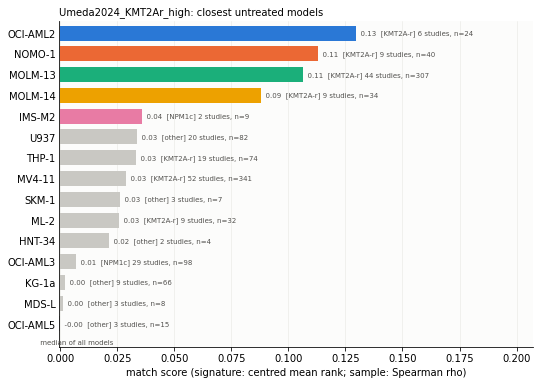

In [7]:
al.pl.match_ranking(mt, n_top=15, highlight=5)

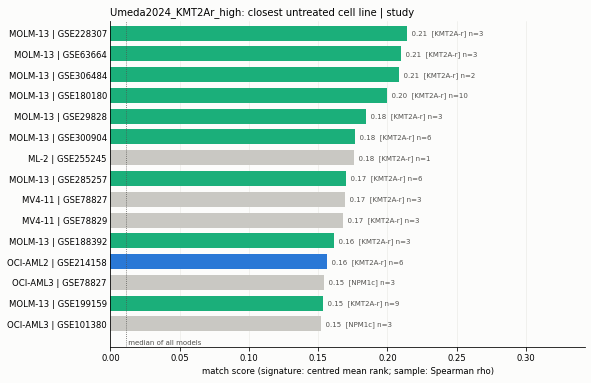

In [8]:
al.pl.match_ranking(mt, by="study", n_top=15)     # cell line | study pairs

**Pseudotime.**
- **Top panel:** every untreated sample in the atlas (grey), with the most similar lines in colour.
- **Bottom panel:** only the matched lines, each untreated sample coloured by its own match score (viridis). The black tick marks the line's mean position.

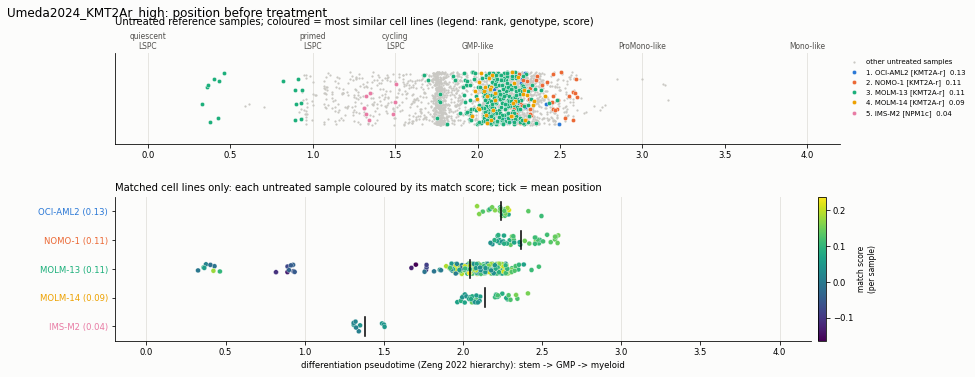

In [9]:
al.pl.pseudotime(mt, n_top=5)

## Step 2: rank the drugs tested in the chosen cell lines
Pass `cell_lines` as a number (the top n of the match) or as names, e.g. only the KMT2A-r lines.

In [10]:
dr = al.tl.rank_drugs(atlas, mt, cell_lines=5)
dr

DrugResult 'Umeda2024_KMT2Ar_high': 61 drugs from 140 contrasts in 5 cell lines (OCI-AML2, NOMO-1, MOLM-13, MOLM-14, IMS-M2)
  top: ziftomenib (T3), gilteritinib + MI-3454 (T3), pinometostat (T1), carbocyclic 5-aza-dC (T3), MI-3454 (T3)
  .drugs .contrasts .classes .top(n)

In [11]:
dr.drugs.head(10)

,rank,drug_name,tier,score,composite,magnitude_z,reversal_z,diff_shift,consistency,n_contrasts,...,myeloid_treated,primitive_control,primitive_treated,surface_mean_lfc,n_surface_up,n_surface_down,surface_net_index,surface_intensity,surface_up_genes,signature_change
drug_key,,,,,,,,,,,,,,,,,,,,,
ziftomenib,1,ziftomenib,T3,1.297978,2.595955,1.787865,3.000000,0.428877,1.000000,1,...,-0.092323,-0.345317,-0.384258,0.101219,150.000000,69.000000,0.125581,1.019298,"CLEC5A +7.9, CD14 +7.6, CR1 +6.1, CLEC12A +5.6, CEACAM4 ...",-2.098468
gilteritinib + MI-3454,2,gilteritinib + MI-3454,T3,1.148981,2.297962,0.893886,3.000000,0.447949,1.000000,1,...,-0.031692,-0.206294,-0.257432,0.080203,197.000000,122.000000,0.052374,0.669232,"CYBB +5.1, FCAR +4.7, CD101 +4.3, SLC8A1 +4.2, CD36 +4.0...",-0.825372
pinometostat,3,pinometostat,T1,1.072884,1.170418,0.460812,1.450413,0.174418,1.000000,11,...,-0.039894,-0.255666,-0.247943,0.138038,213.974713,66.963474,0.122398,0.726942,"CD14 +2.5, ANPEP +2.5, CLEC12A +2.4, JAML +2.3, ADAM28 +...",-0.532107
carbocyclic 5-aza-dC,4,carbocyclic 5-aza-dC,T3,0.985480,1.970959,2.461570,2.181888,0.110383,1.000000,1,...,-0.057502,-0.216621,-0.202792,-0.220560,192.000000,514.000000,-0.235897,1.154700,"STAB1 +5.7, FPR2 +5.2, FPR1 +5.0, XPNPEP2 +4.1, ADGRE3 +...",-0.588475
MI-3454,5,MI-3454,T3,0.975291,1.950581,0.000000,3.000000,0.221813,1.000000,1,...,-0.041445,-0.206294,-0.217172,0.053122,116.000000,65.000000,0.038145,0.477280,"CYBB +4.3, ANPEP +3.7, CLEC12A +3.6, FCAR +3.5, CD101 +3...",-0.795269
selumetinib,6,selumetinib,T2,0.884378,1.179171,0.987434,1.641616,0.084964,0.666667,3,...,-0.008345,-0.197304,-0.194983,0.180542,259.625000,63.500000,0.134909,0.656713,"CSF1R +3.9, CEACAM8 +3.4, P2RY13 +3.1, TLR4 +3.0, CD36 +...",-0.461622
GSK2830371 + nutlin-3a,7,GSK2830371 + nutlin-3a,T2,0.830955,1.107941,1.435467,1.453838,0.051588,1.000000,3,...,-0.065632,-0.335099,-0.321569,0.019706,253.000000,211.666667,0.048891,1.142007,"CD36 +4.5, TNFRSF9 +3.5, SLC39A8 +3.0, AQP9 +2.4, OR5B21...",-0.417533
SGC0946,8,SGC0946,T3,0.723434,1.446869,0.773718,1.448531,0.170167,1.000000,1,...,0.001059,-0.213527,-0.203580,0.235866,279.000000,41.000000,0.171593,0.733091,"FCGR3B +6.5, STEAP4 +6.0, FPR1 +6.0, VNN2 +5.9, CD14 +5....",-0.416287
azacitidine + venetoclax,9,azacitidine + venetoclax,T3,0.714000,1.427999,1.843489,-0.559491,0.235786,1.000000,1,...,0.301998,0.328827,0.306737,-0.149466,36.000000,137.000000,-0.054832,0.482964,"FAM187B +1.6, SCTR +1.5, C5AR2 +1.5, CADM3 +1.4, TM4SF18...",0.055183


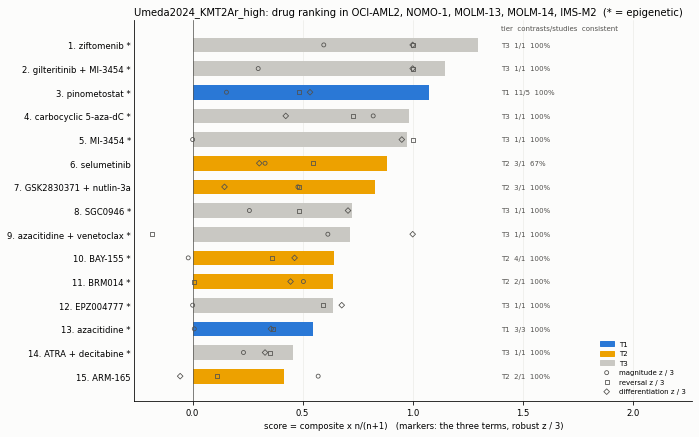

In [12]:
al.pl.drug_ranking(dr, n_top=15)                       # bars = score; markers = the three terms

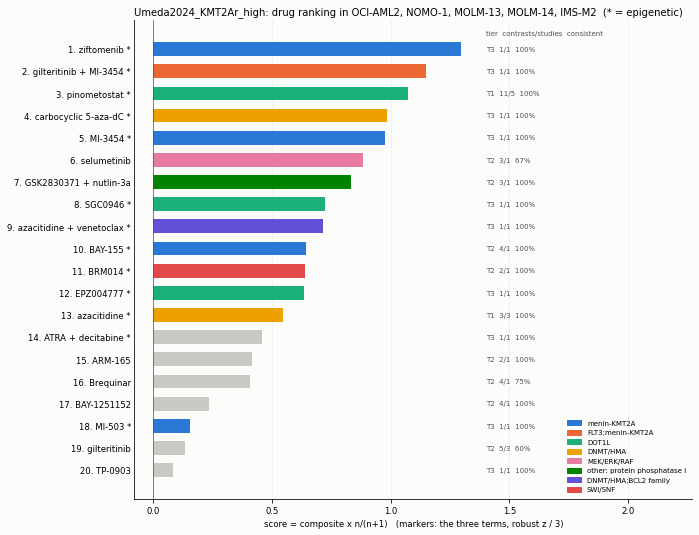

In [13]:
al.pl.drug_ranking(dr, n_top=20, color_by="drug_class", components=False)

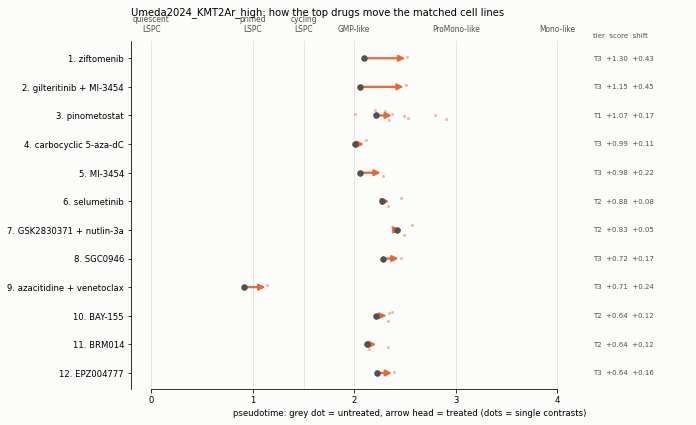

In [14]:
al.pl.drug_shifts(dr, n_top=12)                        # untreated -> treated pseudotime per drug

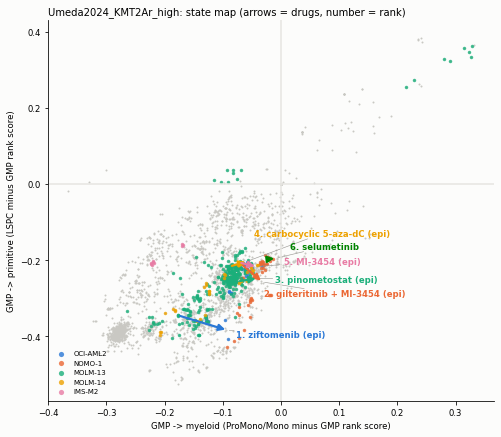

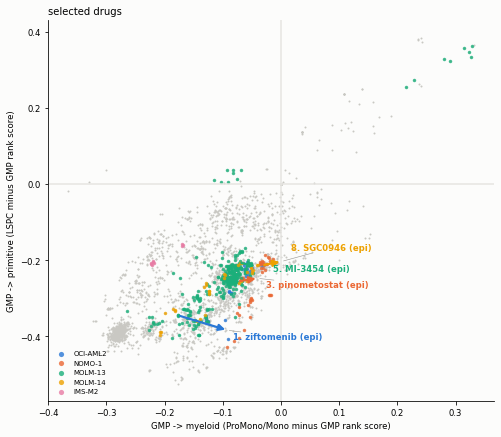

In [15]:
al.pl.state_map(dr, n_top=6)                           # top 6 drugs ...
al.pl.state_map(dr, drugs=["ziftomenib", "pinometostat", "MI-3454", "SGC0946"], title="selected drugs")   # ... or by name

## Drug classes

In [16]:
dr.classes.head(10)

,drug_class,n_contrasts,n_drugs,n_studies,composite,pt_control,pt_treated,diff_shift,diff_shift_q25,diff_shift_q75,frac_toward_myeloid,myeloid_control,myeloid_treated,primitive_control,primitive_treated,d_myeloid,d_primitive,top_drugs
0,VEGFR/FGFR/RTK (other),1,1,1,0.161570,1.957597,2.146456,0.188859,0.188859,0.188859,1.000000,-0.218293,-0.166029,-0.364245,-0.371074,0.052264,-0.006829,TP-0903
1,DOT1L,14,4,7,1.147147,2.175436,2.360341,0.167149,0.065900,0.285522,0.857143,-0.071252,-0.035119,-0.227419,-0.224691,0.032675,0.005996,"SGC0946, EPZ004777, pinometostat"
2,menin-KMT2A,10,7,5,1.024325,2.125687,2.313415,0.122397,0.072545,0.215100,1.000000,-0.076618,-0.053949,-0.233148,-0.241289,0.020471,-0.008071,"ziftomenib, gilteritinib + MI-3454, MI-3454"
3,topoisomerase,2,2,1,-0.212421,2.088574,2.177450,0.088876,0.083188,0.094563,1.000000,-0.097589,-0.081449,-0.248047,-0.244907,0.016140,0.003140,"cytarabine + daunorubicin, daunorubicin"
4,DHODH (pyrimidine synthesis),4,1,1,0.531467,2.195536,2.313929,0.070383,0.051389,0.113944,1.000000,-0.059042,-0.051349,-0.224121,-0.225482,0.011168,-0.003050,Brequinar
5,FLT3,12,6,7,0.155512,2.072370,2.163601,0.054673,0.030413,0.087995,0.833333,-0.100433,-0.093879,-0.253104,-0.257610,0.014665,0.004235,"gilteritinib + MI-3454, gilteritinib, midostaurin"
6,nucleotide synthesis / antimetabolite,4,2,2,-0.306334,2.216055,2.269326,0.051306,0.000033,0.101233,0.750000,-0.084771,-0.073759,-0.251707,-0.249851,0.008809,0.002065,"cytarabine + daunorubicin, cytarabine"
7,retinoid / differentiation,9,5,5,-0.355333,2.293598,2.384094,0.027597,-0.025933,0.063016,0.666667,-0.090322,-0.081544,-0.236978,-0.252672,0.000177,-0.009467,"ATRA + decitabine, ATRA, arsenic trioxide + ATRA"
8,HDAC,5,4,3,-0.583710,2.412736,2.453689,0.027597,0.004651,0.029062,1.000000,-0.095677,-0.075963,-0.358428,-0.322181,0.017964,0.037667,"romidepsin, Linifanib + vorinostat, vorinostat"
9,epigenetic reader (other),1,1,1,-0.112971,2.030528,2.057870,0.027342,0.027342,0.027342,1.000000,-0.091472,-0.085880,-0.220052,-0.219631,0.005592,0.000421,dBRD9


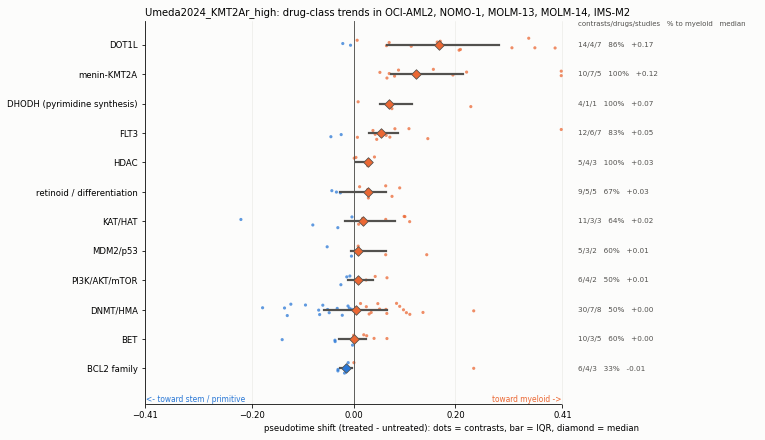

In [17]:
al.pl.class_trends(dr, n_top=12)

classes with < 2 contrasts in the selected cell lines: ['BCL2']


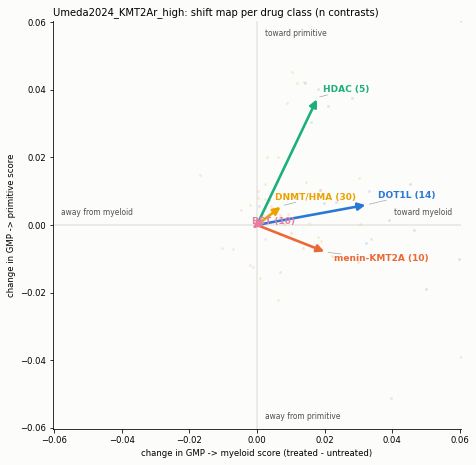

In [18]:
al.pl.class_shift_map(dr, classes=["menin-KMT2A", "DOT1L", "BET", "DNMT/HMA", "HDAC", "BCL2"])

## Genes of interest
`gene_changes` shows any genes per drug (or class) × cell line. Colour is log2FC, size is the number of comparisons, and a hollow dot means the gene isn't expressed.

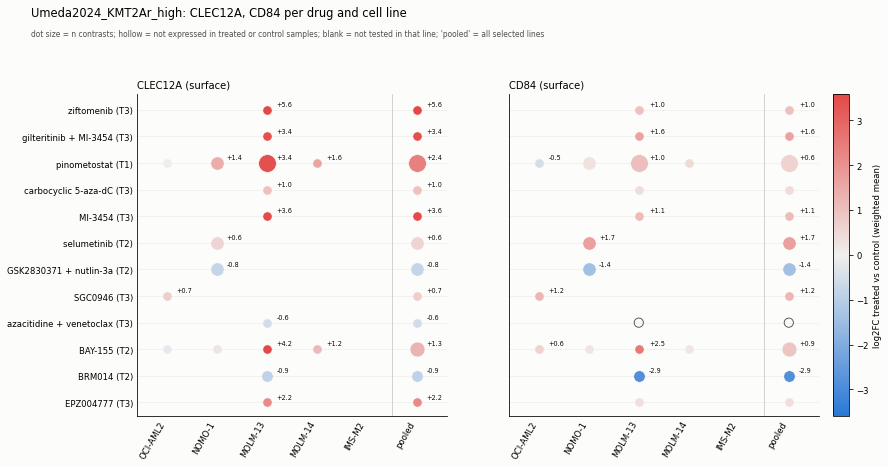

In [19]:
al.pl.gene_changes(dr, genes=["CLEC12A", "CD84"], n_top=12)

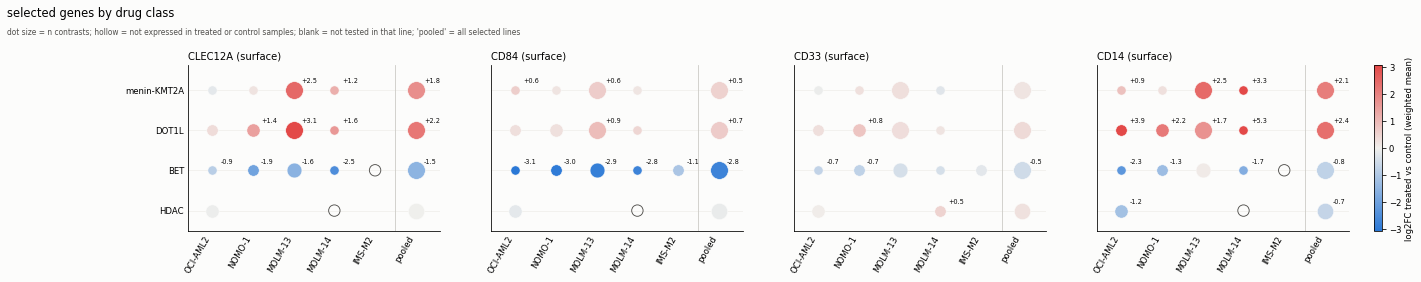

In [20]:
al.pl.gene_changes(dr, genes=["CLEC12A", "CD84", "CD33", "CD14"], classes=["menin-KMT2A", "DOT1L", "BET", "HDAC"],
                   title="selected genes by drug class")

In [21]:
al.tl.gene_changes(dr, ["CLEC12A", "CD84"]).query("cell_line == 'pooled'").round(2)   # the numbers behind the plot

,gene,row,cell_line,mean_log2fc,n_contrasts,expressed,frac_up,frac_down
1,CLEC12A,ziftomenib (T3),pooled,5.59,1,True,1.00,0.00
3,CLEC12A,gilteritinib + MI-3454 (T3),pooled,3.42,1,True,1.00,0.00
8,CLEC12A,pinometostat (T1),pooled,2.37,11,True,0.82,0.00
10,CLEC12A,carbocyclic 5-aza-dC (T3),pooled,0.99,1,True,0.00,0.00
12,CLEC12A,MI-3454 (T3),pooled,3.55,1,True,1.00,0.00
14,CLEC12A,selumetinib (T2),pooled,0.58,3,True,0.67,0.00
16,CLEC12A,GSK2830371 + nutlin-3a (T2),pooled,-0.76,3,True,0.00,0.33
18,CLEC12A,SGC0946 (T3),pooled,0.73,1,True,0.00,0.00
20,CLEC12A,azacitidine + venetoclax (T3),pooled,-0.57,1,True,0.00,0.00
25,CLEC12A,BAY-155 (T2),pooled,1.27,4,True,0.50,0.00


**Top gene changes per drug.**
- **A:** change indices. The net index is (genes up − genes down) / expressed genes; intensity is the mean |log2FC|.
- **B:** the most changed surface (SURFY) genes.
- **C:** the most changed protein-coding genes.

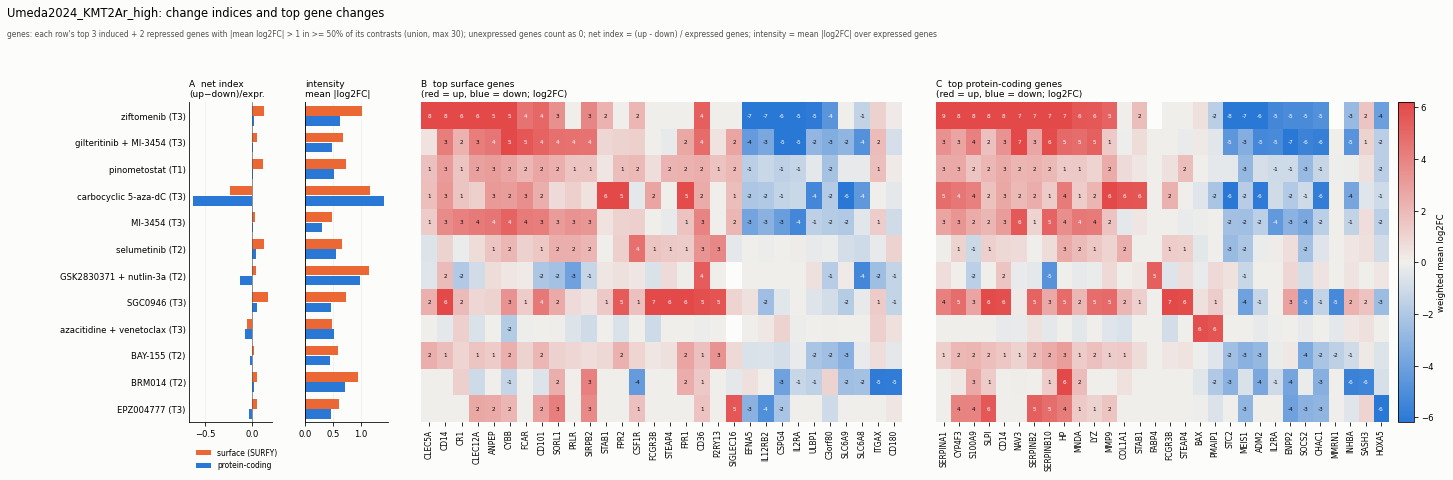

In [22]:
al.pl.top_gene_changes(dr, n_top=12)

**The signature itself**: how each drug moves the query's up genes (orange labels) and down genes (blue labels). A reversal shows as blue up-genes and red down-genes, with a negative bar on the left.

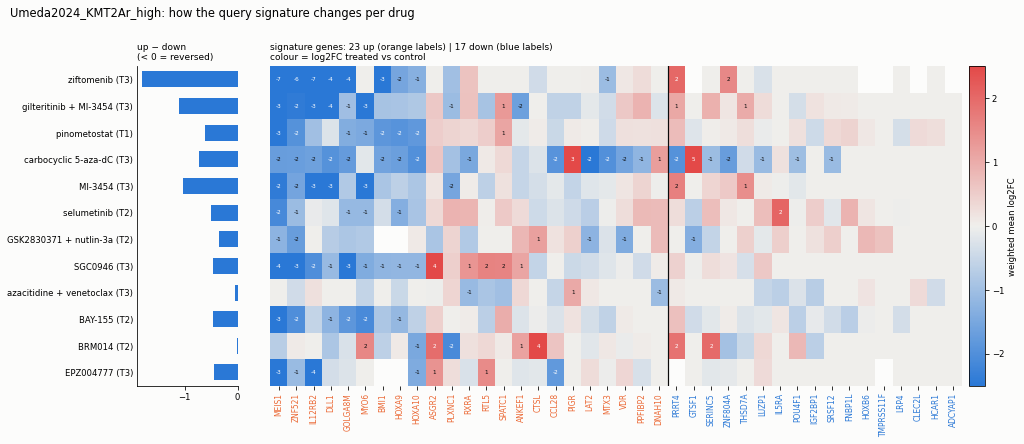

In [23]:
al.pl.signature_changes(dr, n_top=12)

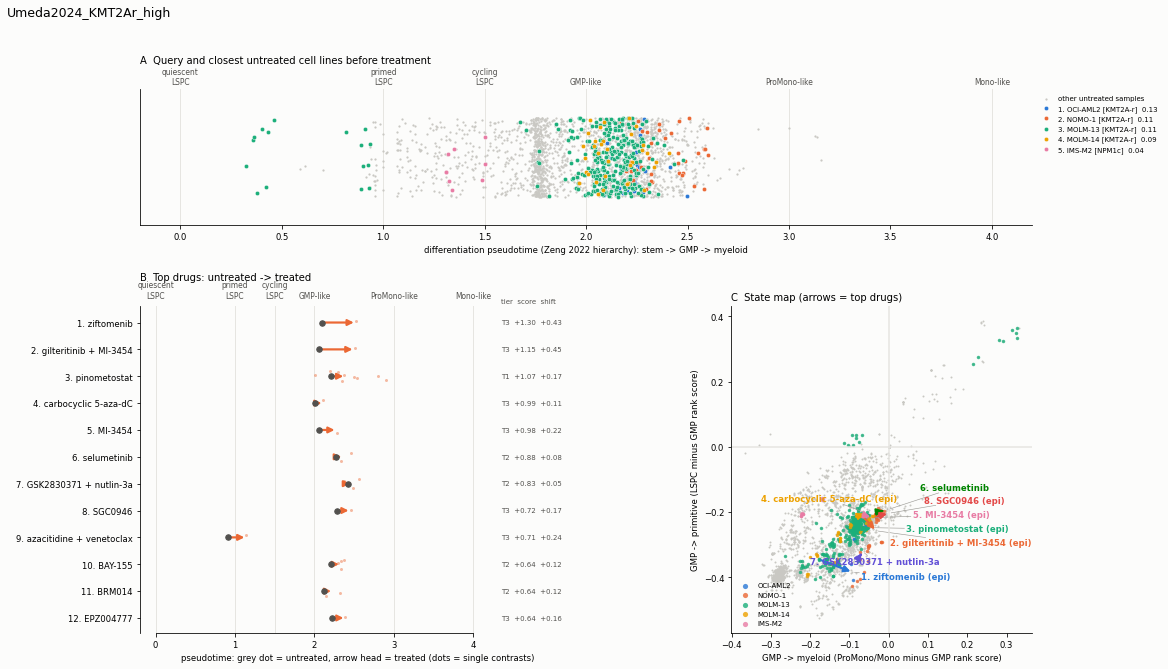

In [24]:
al.pl.summary(mt, dr, n_top=12, save=True)        # three-panel overview, saved to figures/

## Your choice of cell lines
After seeing the match, you can rank drugs in exactly the lines you trust. Here that is the four KMT2A-r lines, leaving out IMS-M2.

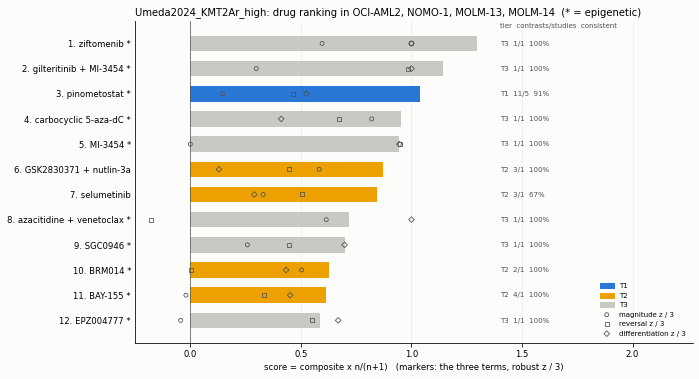

In [25]:
dr_kmt2a = al.tl.rank_drugs(atlas, mt, cell_lines=["OCI-AML2", "NOMO-1", "MOLM-13", "MOLM-14"])
al.pl.drug_ranking(dr_kmt2a, n_top=12)

## Several signatures at once

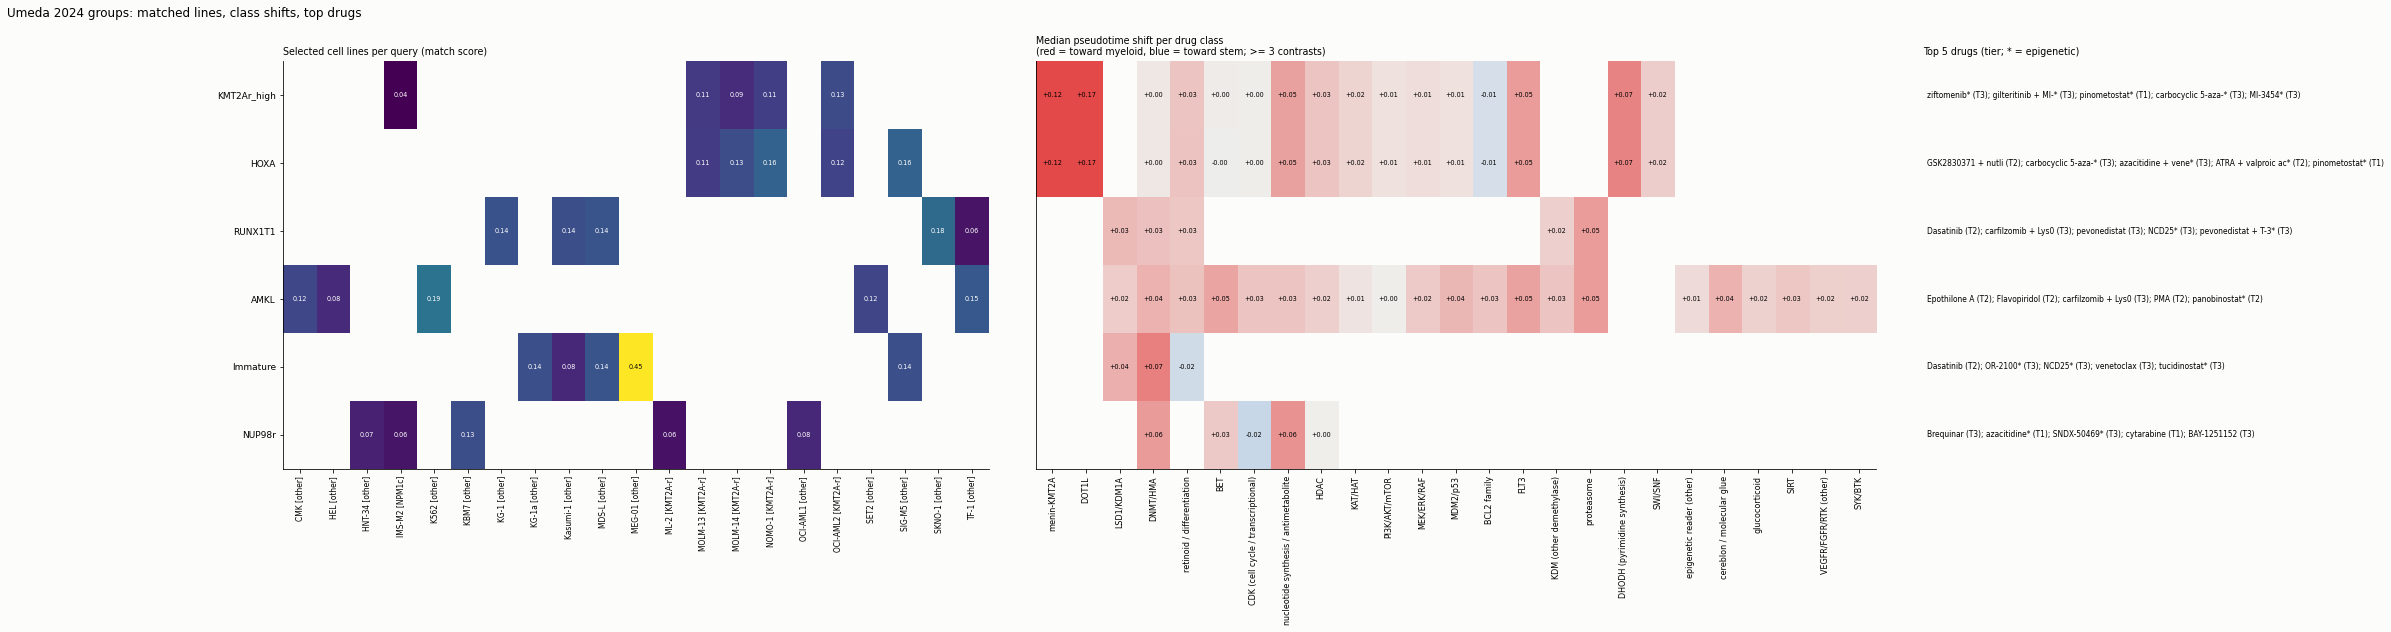

In [26]:
res = {}
for g in ["KMT2Ar_high", "HOXA", "RUNX1T1", "AMKL", "Immature", "NUP98r"]:
    m = al.tl.match(atlas, f"Umeda2024_{g}")
    res[g] = (m, al.tl.rank_drugs(atlas, m, cell_lines=5))
al.pl.group_summary(res, title="Umeda 2024 groups: matched lines, class shifts, top drugs")

In [27]:
# export any table
mt.table.to_csv("figures/KMT2Ar_high_cell_lines.tsv", sep="\t")
dr.drugs.to_csv("figures/KMT2Ar_high_drugs.tsv", sep="\t")
al.tl.surface_genes(dr).to_csv("figures/KMT2Ar_high_surface_genes.tsv", sep="\t", index=False)